# Options Flow, Delta y Gamma · gráficos orientados a decisiones

1. Actividad nueva comparable por strike/vencimiento. 2. Contratos con mayor incremento y cambio de IV. 3. Sensibilidad Delta/Gamma ante un spot hipotético. Edita la configuración, ejecuta todas las celdas y consulta las tablas completas en la terminal. Las capturas no revelan la dirección de las órdenes.

In [1]:
# 1. CAMBIA ESTOS PARÁMETROS Y VUELVE A EJECUTAR LAS CELDAS
RUTA_INFORME = 'ejemplos/informe_sintetico.json'  # Relativa a la raíz del proyecto o ruta absoluta.

RUTA_CONTRATOS = 'ejemplos/contratos_sinteticos_2.csv'  # Mismo snapshot que el informe.

# Filtros de contenido: cambian qué datos se dibujan, no los cálculos guardados.
FILTROS = {
    "vencimientos": [],         # [] = todos; ejemplo: ["2026-11-17"]
    "tipos": ["CALL", "PUT"], # quita un tipo para ocultarlo
    "strike_min": None,
    "strike_max": None,
    "distancia_spot_pct": 0.12, # None para mostrar todos
    "max_strikes": 40,         # None para mostrar todos
}

# Apariencia: todos los colores y tamaños están aquí y puedes cambiar el código de cada figura.
ESTILO = {
    "tema": "default",       # "dark_background" para tema oscuro
    "colores": {"CALL": "#167dba", "PUT": "#e58a35", "positivo": "#148a73",
                "negativo": "#c74b59", "spot": "#7e57c2", "volumen": "#8898a5"},
    "figsize": (12, 5),
    "dpi": 150,
    "fuente": "DejaVu Sans",
    "tamano_fuente": 10,
    "ancho_barra": None,     # None = automático según distancia entre strikes
    "grosor_linea": 1.2,
    "opacidad": 0.85,
    "escala_y": "linear",  # también "symlog"
    "divisor_unidades": 1000, # 1, 1000 o 1_000_000, por ejemplo
    "prefijo_titulo": "",
    "titulos": {},        # ejemplo: {"mapa_actividad": "Mi mapa de actividad"}
    "etiquetas_x": {},    # ejemplo: {"mapa_actividad": "Strike (USD)"}
    "limites_y": {},      # ejemplo: {"sensibilidad_gamma": (-100, 100)}
    "etiquetas": {},  # ejemplo: {"sensibilidad_gamma": "Unidades por 1%"}
}

# Claves de títulos/etiquetas/límites: mapa_actividad, ranking_actividad, cambio_iv,
# sensibilidad_delta y sensibilidad_gamma.
SERIES = {
    "mapa_actividad": True, "ranking_actividad": True,
    "sensibilidad_spot": True, "escenario_dealer": True,
    "mostrar_spot": True, "linea_cero": True, "cuadricula": True,
    "leyenda": True, "anotaciones": True, "max_anotaciones": 8,
}

# Parámetros de contenido de las nuevas figuras.
ANALISIS = {
    "top_contratos": 12,
    "tamano_burbujas": 45,  # escala visual de sqrt(incremento de volumen)
    "rango_spot_pct": 0.05,
    "puntos_spot": 61,
}

EXPORTACION = {
    "activar": False,
    "carpeta": 'resultados/graficas_demo',
    "formatos": ["png"],  # también "svg" o "pdf"
    "fondo_transparente": False,
    "sobrescribir": False,
}


In [2]:
from pathlib import Path
import hashlib, json, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from options_flow.griegas import delta_gamma

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLAN_REDISENO.md").exists()), None)
if RAIZ is None:
    raise FileNotFoundError("Abre el notebook dentro del proyecto kronos")
def resolver(ruta):
    p = Path(ruta)
    return (p if p.is_absolute() else RAIZ / p).resolve()
RUTA = resolver(RUTA_INFORME)
RUTA_CSV = resolver(RUTA_CONTRATOS)
contenido = RUTA.read_bytes()
informe = json.loads(contenido)
huella_informe = hashlib.sha256(contenido).hexdigest()
bytes_csv = RUTA_CSV.read_bytes()
if hashlib.sha256(bytes_csv).hexdigest() != informe["captura_actual"]["sha256_csv"]:
    raise ValueError("El CSV de contratos no pertenece al informe seleccionado")
contratos = pd.read_csv(RUTA_CSV, dtype={"id_contrato": str})
meta = informe["captura_actual"]["metadatos"]
spot = float(meta["spot"])
simbolo = meta["subyacente"]
plt.style.use(ESTILO["tema"])
plt.rcParams.update({"font.family": ESTILO["fuente"], "font.size": ESTILO["tamano_fuente"]})
display(Markdown(
    f"**Fuente:** `{RUTA}`  \n**Contratos:** `{RUTA_CSV}`  \n"
    f"**Activo:** {simbolo} · **Spot:** {spot:g} · **Captura UTC:** {meta['capturado_en_utc']}  \n"
    f"**SHA-256 del informe:** `{huella_informe}`  \n"
    "El volumen entre capturas es una estimación; la sensibilidad es un escenario con IV y tiempo constantes."
))


**Fuente:** `D:\02_Herramientas\kronos\ejemplos\informe_sintetico.json`  
**Contratos:** `D:\02_Herramientas\kronos\ejemplos\contratos_sinteticos_2.csv`  
**Activo:** QQQ · **Spot:** 600.8 · **Captura UTC:** 2026-11-16T15:05:00+00:00  
**SHA-256 del informe:** `ba7b1a3ffe9371b2fcc6c4e1a8bfc33c4e4ea1ed1b3c902770b1c1ecd97108fe`  
El volumen entre capturas es una estimación; la sensibilidad es un escenario con IV y tiempo constantes.

In [3]:
def filtrar(tabla):
    if tabla.empty:
        return tabla.copy()
    tabla = tabla.copy()
    tabla["strike"] = pd.to_numeric(tabla["strike"], errors="coerce")
    tabla = tabla.dropna(subset=["strike"])
    if FILTROS["vencimientos"]:
        tabla = tabla[tabla["vencimiento"].isin(FILTROS["vencimientos"])]
    tabla = tabla[tabla["tipo"].isin(FILTROS["tipos"])]
    if FILTROS["strike_min"] is not None:
        tabla = tabla[tabla["strike"] >= FILTROS["strike_min"]]
    if FILTROS["strike_max"] is not None:
        tabla = tabla[tabla["strike"] <= FILTROS["strike_max"]]
    if FILTROS["distancia_spot_pct"] is not None:
        d = spot * FILTROS["distancia_spot_pct"]
        tabla = tabla[tabla["strike"].between(spot-d, spot+d)]
    maximo = FILTROS["max_strikes"]
    if maximo and tabla["strike"].nunique() > maximo:
        elegidos = sorted(tabla["strike"].unique(), key=lambda x: abs(x-spot))[:maximo]
        tabla = tabla[tabla["strike"].isin(elegidos)]
    return tabla.copy()

def titulo(clave, defecto):
    return ESTILO["prefijo_titulo"] + ESTILO["titulos"].get(clave, defecto)

def etiqueta_x(clave, defecto):
    return ESTILO["etiquetas_x"].get(clave, defecto)

def etiqueta_y(clave, defecto):
    return ESTILO["etiquetas"].get(clave, defecto)

def limite_y(ax, clave):
    if clave in ESTILO["limites_y"]:
        ax.set_ylim(*ESTILO["limites_y"][clave])

def decorar(ax, titulo, xlabel, ylabel, *, spot_vertical=False, spot_horizontal=False):
    ax.set_title(ESTILO["prefijo_titulo"] + titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_yscale(ESTILO["escala_y"] if not spot_horizontal else "linear")
    if SERIES["linea_cero"]:
        ax.axhline(0, color=ESTILO["colores"]["volumen"], lw=ESTILO["grosor_linea"], alpha=0.5)
    if SERIES["mostrar_spot"] and spot_vertical:
        ax.axvline(spot, color=ESTILO["colores"]["spot"], lw=ESTILO["grosor_linea"], ls="--", label="Spot")
    if SERIES["cuadricula"]:
        ax.grid(True, alpha=0.2)
    if SERIES["leyenda"]:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend()

def mostrar(fig, nombre):
    fig.tight_layout(pad=2)
    if EXPORTACION["activar"]:
        carpeta = resolver(EXPORTACION["carpeta"])
        carpeta.mkdir(parents=True, exist_ok=True)
        config = json.dumps([FILTROS, ESTILO, SERIES, ANALISIS, EXPORTACION], sort_keys=True, default=str)
        clave = hashlib.sha256((huella_informe + config).encode()).hexdigest()[:10]
        seguro = re.sub(r"[^A-Za-z0-9_-]", "_", nombre)
        for formato in EXPORTACION["formatos"]:
            destino = carpeta / f"{simbolo}_{seguro}_{clave}.{formato}"
            if destino.exists() and not EXPORTACION["sobrescribir"]:
                print(f"Imagen existente: {destino}")
            else:
                fig.savefig(destino, dpi=ESTILO["dpi"], transparent=EXPORTACION["fondo_transparente"], bbox_inches="tight")
                print(f"Imagen exportada: {destino}")
    display(fig)
    plt.close(fig)

def actividad_nueva():
    comparacion = informe.get("actividad")
    if comparacion is None:
        print("Sin comparación de capturas: no hay actividad intradía estimada")
        return pd.DataFrame()
    if not comparacion["misma_fecha_mercado"]:
        print("Las capturas son de distintos días de mercado: no hay incremento intradía comparable")
        return pd.DataFrame()
    tabla = filtrar(pd.DataFrame(comparacion["contratos"]))
    if tabla.empty:
        print("Sin contratos de actividad con estos filtros")
        return tabla
    tabla["incremento_volumen_estimado"] = pd.to_numeric(tabla["incremento_volumen_estimado"], errors="coerce")
    tabla["cambio_iv"] = pd.to_numeric(tabla["cambio_iv"], errors="coerce")
    nuevas = tabla[(tabla["estado_volumen"] == "COMPARABLE") &
                   (tabla["incremento_volumen_estimado"] > 0)].copy()
    if nuevas.empty:
        print("Sin incrementos de volumen comparables en la selección; no se crea una figura vacía")
    return nuevas


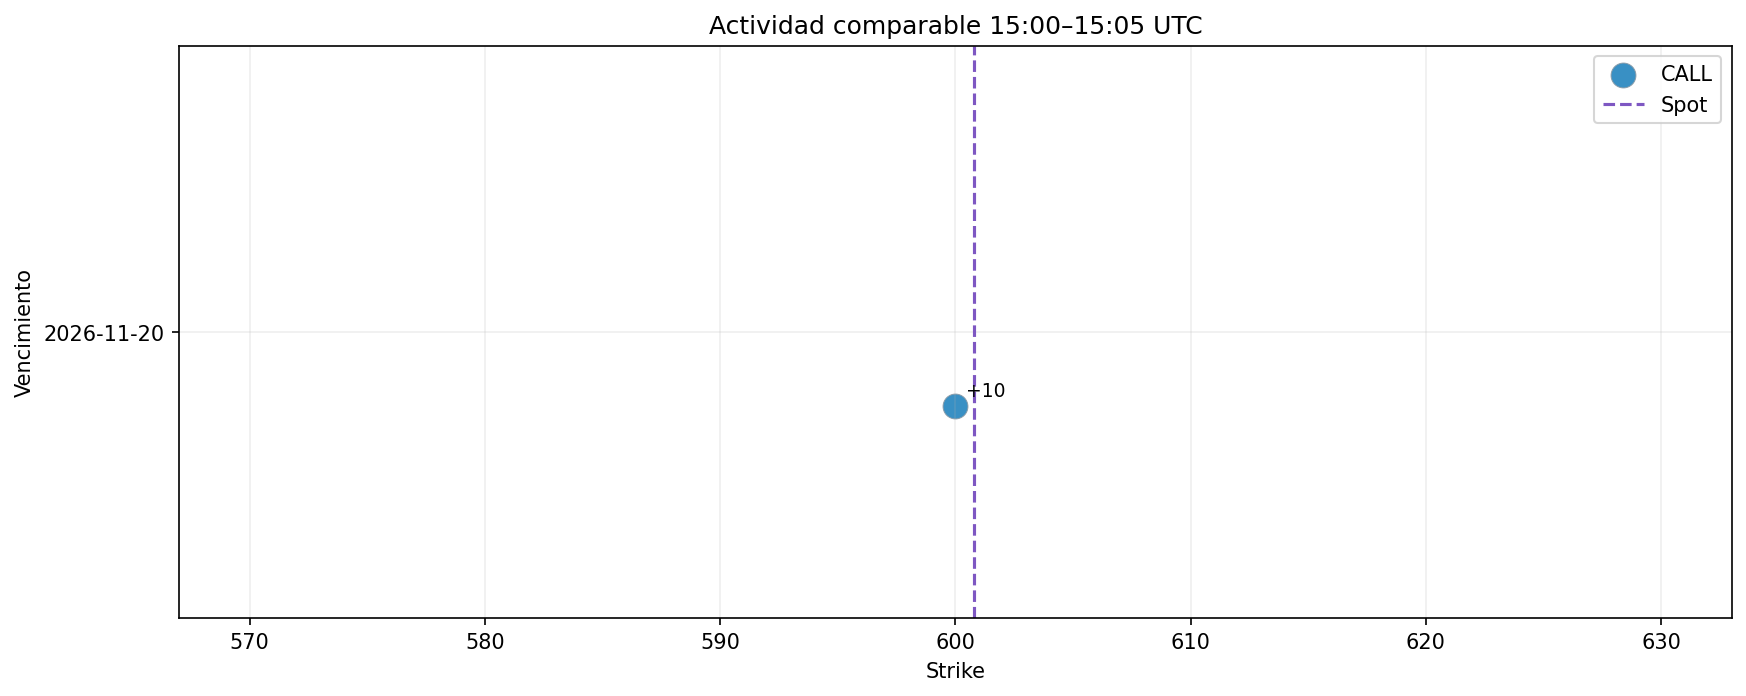

In [4]:
# 2. Dónde apareció actividad entre dos capturas del mismo día.
nuevas = actividad_nueva()
if SERIES["mapa_actividad"] and not nuevas.empty:
    fechas = sorted(nuevas["vencimiento"].unique())
    posiciones = {fecha: i for i, fecha in enumerate(fechas)}
    desplazamiento = {"CALL": -0.13, "PUT": 0.13}
    fig, ax = plt.subplots(figsize=ESTILO["figsize"], dpi=ESTILO["dpi"])
    for tipo, marcador in [("CALL", "o"), ("PUT", "s")]:
        lado = nuevas[nuevas["tipo"] == tipo]
        if lado.empty:
            continue
        ax.scatter(lado["strike"], lado["vencimiento"].map(posiciones) + desplazamiento[tipo],
                   s=ANALISIS["tamano_burbujas"] * np.sqrt(lado["incremento_volumen_estimado"]),
                   marker=marcador, color=ESTILO["colores"][tipo], alpha=ESTILO["opacidad"],
                   edgecolors=ESTILO["colores"]["volumen"], linewidths=0.5, label=tipo)
    if SERIES["anotaciones"]:
        for fila in nuevas.nlargest(SERIES["max_anotaciones"], "incremento_volumen_estimado").itertuples():
            ax.annotate(f"+{int(fila.incremento_volumen_estimado)}",
                        (fila.strike, posiciones[fila.vencimiento] + desplazamiento[fila.tipo]), xytext=(5, 5),
                        textcoords="offset points", fontsize=ESTILO["tamano_fuente"]-1)
    ax.set_yticks(range(len(fechas)), fechas)
    ax.set_ylim(-0.5, len(fechas)-0.5)
    anterior = informe["captura_anterior"]["metadatos"]["capturado_en_utc"][11:16]
    actual = meta["capturado_en_utc"][11:16]
    ax.set_title(titulo("mapa_actividad", f"Actividad comparable {anterior}–{actual} UTC"))
    ax.set_xlabel(etiqueta_x("mapa_actividad", "Strike"))
    ax.set_ylabel(etiqueta_y("mapa_actividad", "Vencimiento"))
    limite_y(ax, "mapa_actividad")
    if SERIES["mostrar_spot"]:
        ax.axvline(spot, color=ESTILO["colores"]["spot"], ls="--", label="Spot")
    if SERIES["cuadricula"]:
        ax.grid(True, alpha=0.2)
    if SERIES["leyenda"]:
        ax.legend()
    mostrar(fig, "mapa_actividad")


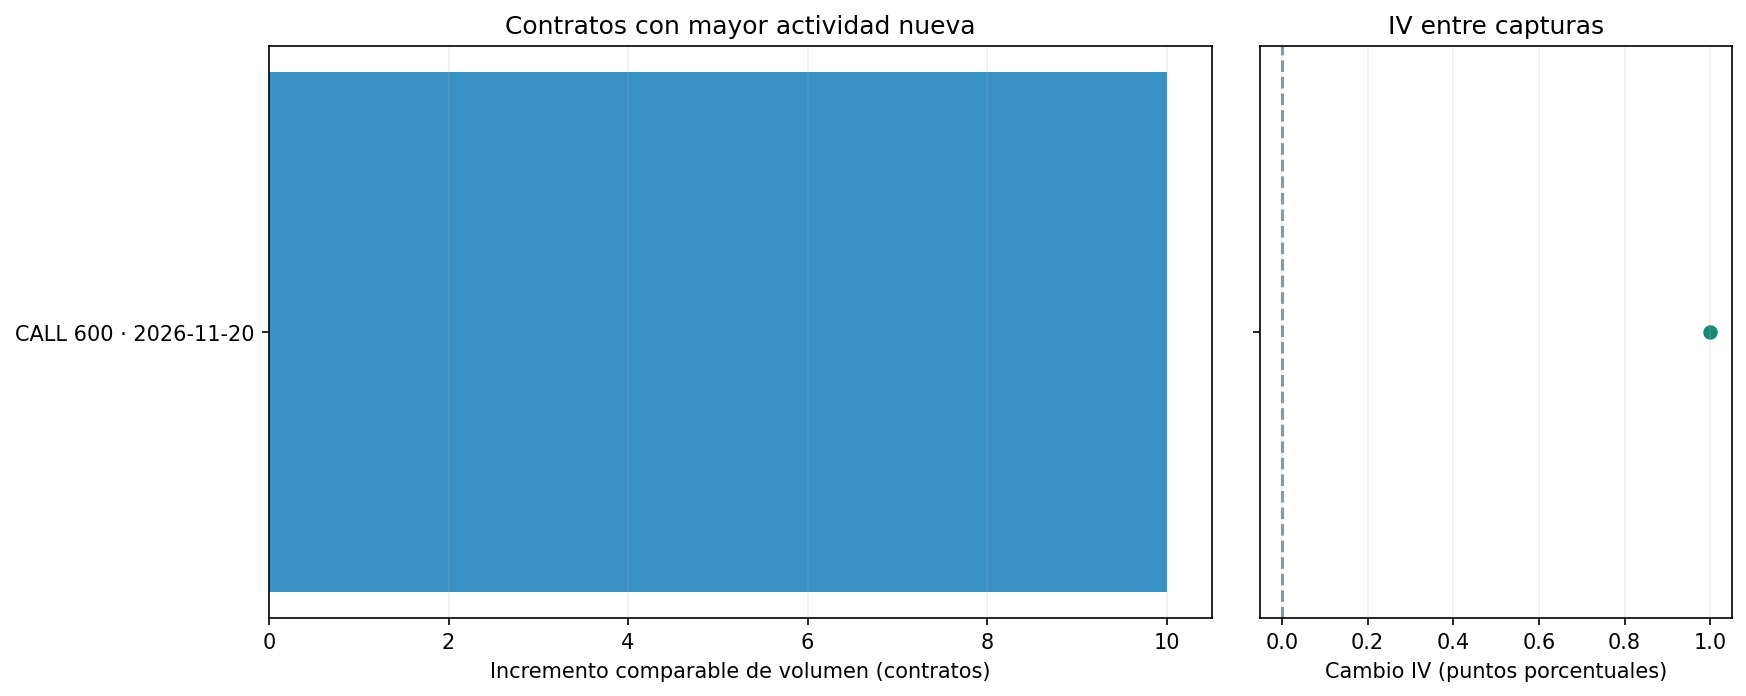

In [5]:
# 3. Contratos con mayor incremento; IV en puntos porcentuales, sin inferir dirección de órdenes.
if SERIES["ranking_actividad"] and not nuevas.empty:
    top = nuevas.nlargest(ANALISIS["top_contratos"], "incremento_volumen_estimado").iloc[::-1]
    etiquetas = [f"{f.tipo} {f.strike:g} · {f.vencimiento}" for f in top.itertuples()]
    alto = max(ESTILO["figsize"][1], len(top)*0.45 + 2)
    fig, (ax, ax_iv) = plt.subplots(1, 2, figsize=(ESTILO["figsize"][0], alto),
                                   dpi=ESTILO["dpi"], sharey=True,
                                   gridspec_kw={"width_ratios": [2, 1]})
    y = np.arange(len(top))
    ax.barh(y, top["incremento_volumen_estimado"],
            color=[ESTILO["colores"][t] for t in top["tipo"]], alpha=ESTILO["opacidad"])
    ax.set_yticks(y, etiquetas)
    ax.set_xlabel(etiqueta_x("ranking_actividad", "Incremento comparable de volumen (contratos)"))
    ax.set_title(titulo("ranking_actividad", "Contratos con mayor actividad nueva"))
    limite_y(ax, "ranking_actividad")
    iv_pp = top["cambio_iv"] * 100
    ax_iv.scatter(iv_pp, y, color=ESTILO["colores"]["positivo"], s=35)
    ax_iv.axvline(0, color=ESTILO["colores"]["volumen"], ls="--")
    ax_iv.set_xlabel(etiqueta_x("cambio_iv", "Cambio IV (puntos porcentuales)"))
    ax_iv.set_title(titulo("cambio_iv", "IV entre capturas"))
    limite_y(ax_iv, "cambio_iv")
    if SERIES["cuadricula"]:
        ax.grid(True, axis="x", alpha=0.2)
        ax_iv.grid(True, axis="x", alpha=0.2)
    mostrar(fig, "ranking_actividad_iv")


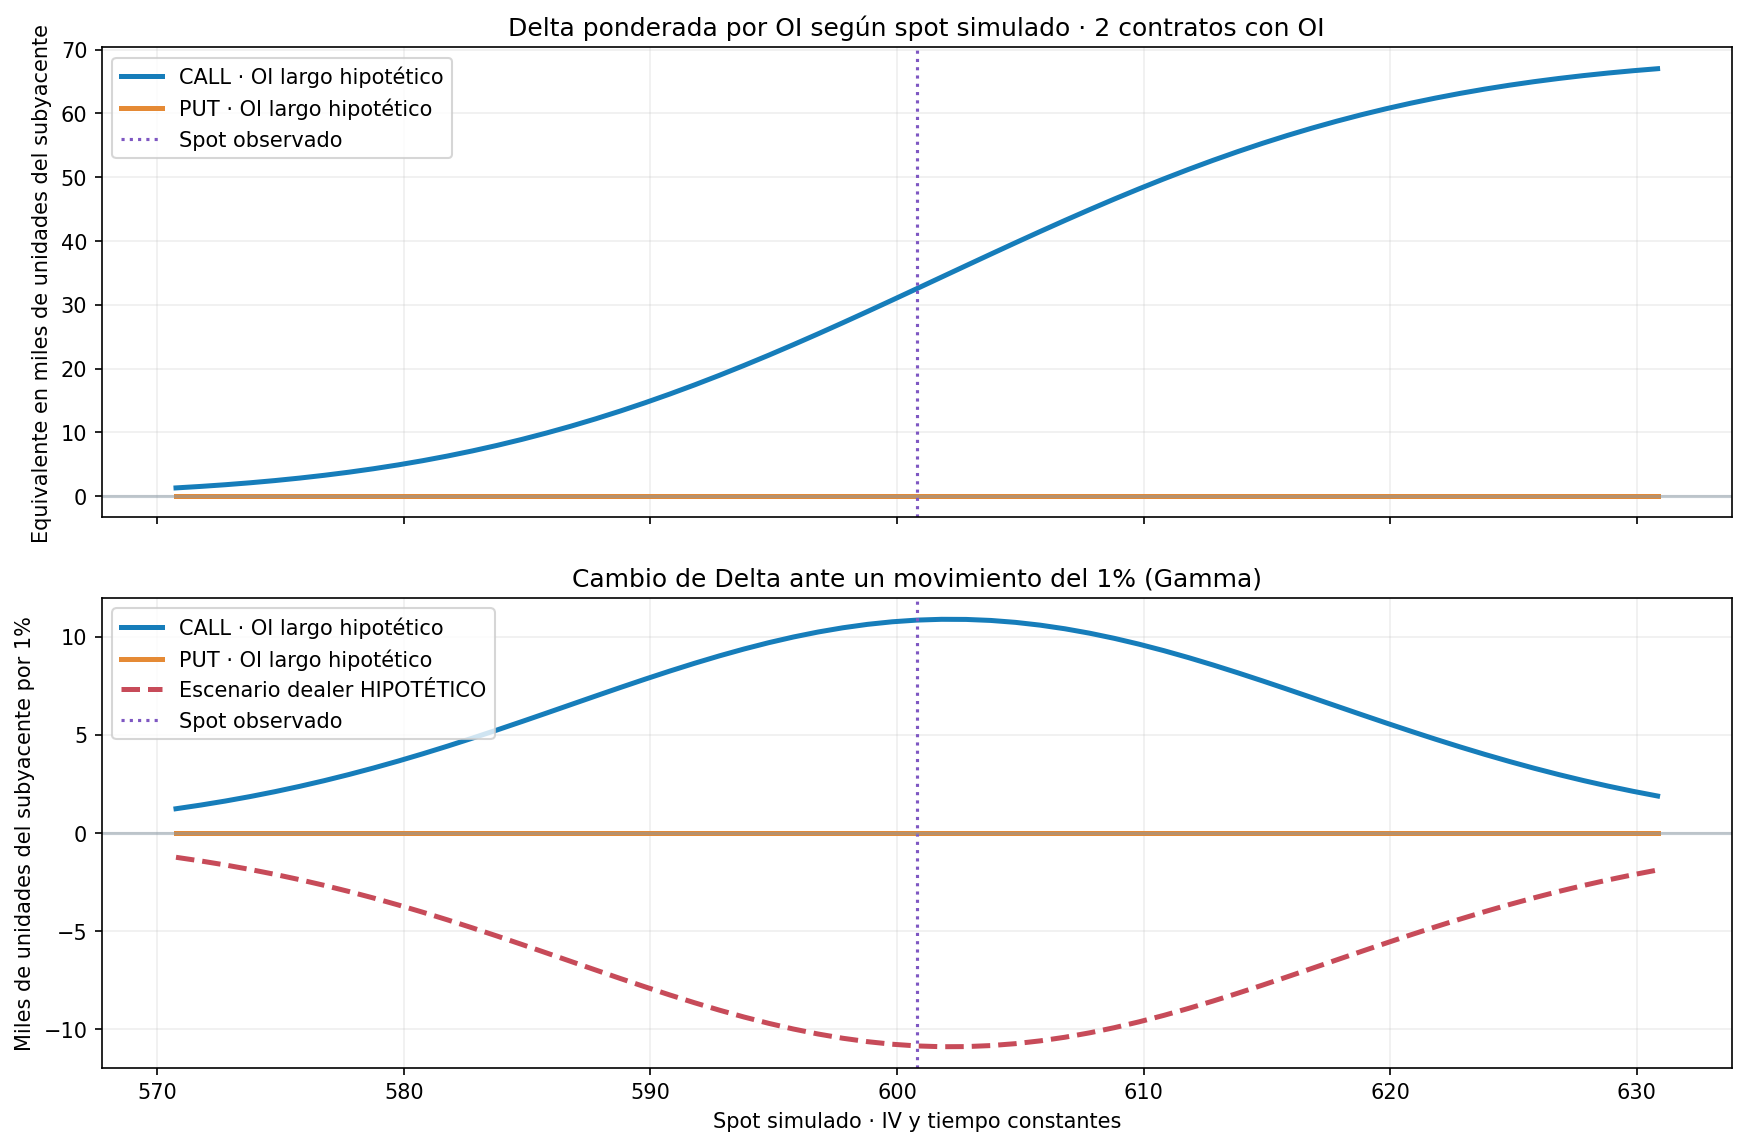

In [6]:
# 4. Qué pasaría con Delta/Gamma si solo cambiase el spot. IV, tiempo, tasa y OI se mantienen fijos.
if SERIES["sensibilidad_spot"]:
    griegas = filtrar(pd.DataFrame(informe["griegas"]))
    oi = contratos[["id_contrato", "open_interest"]].copy()
    oi["open_interest"] = pd.to_numeric(oi["open_interest"], errors="coerce")
    griegas = griegas.merge(oi, on="id_contrato", how="left", validate="one_to_one")
    griegas = griegas.dropna(subset=["open_interest"])
    if griegas.empty:
        print("Sin contratos con Greeks y OI conocidos para sensibilidad")
    else:
        rango = ANALISIS["rango_spot_pct"]
        if not (0 < rango < 1 and ANALISIS["puntos_spot"] >= 3):
            raise ValueError("rango_spot_pct debe estar entre 0 y 1; puntos_spot >= 3")
        precios = np.linspace(spot*(1-rango), spot*(1+rango), ANALISIS["puntos_spot"])
        curvas = {tipo: {"delta": [], "gamma": []} for tipo in FILTROS["tipos"]}
        filas = list(griegas.itertuples())
        for precio in precios:
            acumulado = {tipo: [0.0, 0.0] for tipo in FILTROS["tipos"]}
            for fila in filas:
                d, g = delta_gamma(spot=float(precio), strike=float(fila.strike),
                                   volatilidad=float(fila.volatilidad), tiempo_anos=float(fila.tiempo_anos),
                                   tipo=fila.tipo, tasa_anual=float(fila.tasa_anual),
                                   dividendo_anual=float(fila.dividendo_anual))
                ponderacion = float(fila.open_interest) * int(fila.multiplicador)
                acumulado[fila.tipo][0] += d * ponderacion
                acumulado[fila.tipo][1] += g * ponderacion * precio * 0.01
            for tipo in FILTROS["tipos"]:
                curvas[tipo]["delta"].append(acumulado[tipo][0])
                curvas[tipo]["gamma"].append(acumulado[tipo][1])
        fig, (ax_d, ax_g) = plt.subplots(2, 1, figsize=(ESTILO["figsize"][0], ESTILO["figsize"][1]*1.6),
                                        dpi=ESTILO["dpi"], sharex=True)
        divisor = ESTILO["divisor_unidades"]
        if divisor <= 0:
            raise ValueError("divisor_unidades debe ser positivo")
        unidad = {1: "unidades", 1000: "miles de unidades", 1000000: "millones de unidades"}.get(
            divisor, f"unidades / {divisor}"
        )
        for tipo in FILTROS["tipos"]:
            color = ESTILO["colores"][tipo]
            ax_d.plot(precios, np.array(curvas[tipo]["delta"]) / divisor, color=color, lw=ESTILO["grosor_linea"]*2,
                      label=f"{tipo} · OI largo hipotético")
            ax_g.plot(precios, np.array(curvas[tipo]["gamma"]) / divisor, color=color, lw=ESTILO["grosor_linea"]*2,
                      label=f"{tipo} · OI largo hipotético")
        if SERIES["escenario_dealer"] and informe.get("escenario_dealer_strike") is not None:
            dealer_g = np.zeros(len(precios))
            for tipo in FILTROS["tipos"]:
                dealer_g += np.array(curvas[tipo]["gamma"]) * (-1 if tipo == "CALL" else 1)
            ax_g.plot(precios, dealer_g / divisor, color=ESTILO["colores"]["negativo"], ls="--",
                      lw=ESTILO["grosor_linea"]*2, label="Escenario dealer HIPOTÉTICO")
        for ax in (ax_d, ax_g):
            if SERIES["mostrar_spot"]:
                ax.axvline(spot, color=ESTILO["colores"]["spot"], ls=":" , label="Spot observado")
            if SERIES["linea_cero"]:
                ax.axhline(0, color=ESTILO["colores"]["volumen"], alpha=0.5)
            if SERIES["cuadricula"]:
                ax.grid(True, alpha=0.2)
            if SERIES["leyenda"]:
                ax.legend()
        ax_d.set_title(titulo("sensibilidad_delta", "Delta ponderada por OI según spot simulado") +
                       f" · {len(griegas)} contratos con OI")
        ax_d.set_ylabel(etiqueta_y("sensibilidad_delta", f"Equivalente en {unidad} del subyacente"))
        ax_g.set_title(titulo("sensibilidad_gamma", "Cambio de Delta ante un movimiento del 1% (Gamma)"))
        ax_g.set_ylabel(etiqueta_y("sensibilidad_gamma", f"{unidad.capitalize()} del subyacente por 1%"))
        ax_g.set_xlabel(etiqueta_x("sensibilidad_gamma", "Spot simulado · IV y tiempo constantes"))
        ax_d.set_yscale(ESTILO["escala_y"])
        ax_g.set_yscale(ESTILO["escala_y"])
        limite_y(ax_d, "sensibilidad_delta")
        limite_y(ax_g, "sensibilidad_gamma")
        mostrar(fig, "sensibilidad_delta_gamma_spot")
